# Hierarchical Fractal Molecular Cloud Generator

This notebook implements the cloud-density construction in Section 2.1 of the project proposal.

**Model choices**
- A cubic grid with `GRID_SIZE = 64`.
- `N_BRANCH = 32` initial points and 32 offspring per point.
- Four hierarchical levels in the final point population: \(32^4 = 1,048,576\) points.
- Periodic wrapping at the cube boundaries.
- The point cloud is binned into grid cells; cell density is proportional to its point count.
- A spherical mask is applied to represent the physical cloud inscribed in the supercube.
- An optional uniform component is mixed in by mass fraction.

The proposal does not specify the exact offspring displacement probability distribution or the precise radius convention. Here, offspring are distributed uniformly in a 3-D ball. The maximum displacement at hierarchical level `level` is

\[
r_{\rm level}=L N^{-\mathrm{level}/D},
\]

where \(L\) is the box side length in grid-cell units and \(D\) is the chosen fractal dimension. This is an explicit, tunable realization of the proposal's statement that the offspring scale shrinks according to \(D\).

## 1. User-adjustable parameters

Change the values in this cell and rerun the notebook. `Z` and `A` describe the element used when converting mass density to atomic number density; they do not change the geometric point-generation algorithm.

For a mixture, edit `ELEMENTS` and make sure the mass fractions sum to 1.0.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # registers the 3-D projection
from matplotlib.colors import LogNorm

# -------------------------
# Cloud geometry
# -------------------------
GRID_SIZE = 64           # number of cells along each cube axis
N_BRANCH = 32            # initial points and offspring per parent
N_LEVELS = 4             # total hierarchical levels; final count = N_BRANCH**N_LEVELS
FRACTAL_DIMENSION = 2.3  # try 2.3 or 2.6
RANDOM_SEED = 42

# -------------------------
# Uniform background
# -------------------------
ADD_UNIFORM_BACKGROUND = True
UNIFORM_MASS_FRACTION = 0.33  # set to 0.0 to disable

# -------------------------
# Elemental composition
# -------------------------
# Single-element example: pure hydrogen-1.
Z = 1
A = 1
ELEMENTS = [
    {"name": "H-1", "Z": Z, "A": A, "mass_fraction": 1.0}
]

# Example mixture (uncomment and edit if desired):
# ELEMENTS = [
#     {"name": "H-1", "Z": 1, "A": 1, "mass_fraction": 0.70},
#     {"name": "He-4", "Z": 2, "A": 4, "mass_fraction": 0.28},
#     {"name": "C-12", "Z": 6, "A": 12, "mass_fraction": 0.02},
# ]

print(f"Final number of generated points: {N_BRANCH**N_LEVELS:,}")

Final number of generated points: 1,048,576


## 2. Generate the hierarchical point distribution

Coordinates are measured in grid-cell units, with the cube spanning `[0, GRID_SIZE)` on each axis. Periodic boundaries are implemented with modulo arithmetic.

In [2]:
def random_points_in_ball(rng, n_points, max_radius):
    """Draw points uniformly by volume inside a 3-D ball."""
    direction = rng.normal(size=(n_points, 3))
    direction /= np.linalg.norm(direction, axis=1, keepdims=True)
    radius = max_radius * rng.random(n_points) ** (1.0 / 3.0)
    return direction * radius[:, None]


def generate_fractal_points(
    grid_size=64,
    n_branch=32,
    n_levels=4,
    fractal_dimension=2.3,
    seed=42,
):
    """
    Generate a periodic hierarchical point distribution.

    At level 1, place n_branch points randomly in the cube.
    At each subsequent level, replace every parent with n_branch offspring.
    The final number of points is n_branch**n_levels.
    """
    if fractal_dimension <= 0:
        raise ValueError("fractal_dimension must be positive")
    if n_levels < 1 or n_branch < 1:
        raise ValueError("n_levels and n_branch must be positive")

    rng = np.random.default_rng(seed)

    # First hierarchical level: N uniformly distributed seed points.
    points = rng.uniform(0.0, grid_size, size=(n_branch, 3))

    # Additional levels produce N**n_levels points in total.
    for level in range(1, n_levels):
        # Characteristic maximum offspring displacement at this level.
        radius = grid_size * n_branch ** (-level / fractal_dimension)

        offsets = random_points_in_ball(
            rng,
            n_points=len(points) * n_branch,
            max_radius=radius,
        )

        # Repeat each parent N times, add one offset to each child,
        # and wrap positions back into the periodic supercube.
        parents = np.repeat(points, n_branch, axis=0)
        points = (parents + offsets) % grid_size

    return points


points = generate_fractal_points(
    grid_size=GRID_SIZE,
    n_branch=N_BRANCH,
    n_levels=N_LEVELS,
    fractal_dimension=FRACTAL_DIMENSION,
    seed=RANDOM_SEED,
)

print("Generated point array:", points.shape)

Generated point array: (1048576, 3)


## 3. Bin points into cells and construct the spherical cloud

The sphere is centered at the center of the supercube and has radius `GRID_SIZE / 2`. The density is normalized so that its mean over cells inside the sphere is 1. Thus, the density array is dimensionless until a physical normalization is supplied.

In [3]:
def points_to_density(points, grid_size=64):
    """Histogram point coordinates into a cubic 3-D cell grid."""
    indices = np.floor(points).astype(int) % grid_size
    counts = np.zeros((grid_size, grid_size, grid_size), dtype=np.float64)
    np.add.at(counts, (indices[:, 0], indices[:, 1], indices[:, 2]), 1)
    return counts


def spherical_mask(grid_size=64):
    """Boolean mask for a sphere inscribed in the cubic grid."""
    coords = np.arange(grid_size) + 0.5  # cell centers
    x, y, z = np.meshgrid(coords, coords, coords, indexing="ij")
    center = grid_size / 2.0
    radius = grid_size / 2.0
    return (x-center)**2 + (y-center)**2 + (z-center)**2 <= radius**2


def construct_cloud_density(
    points,
    grid_size=64,
    add_uniform_background=True,
    uniform_mass_fraction=0.33,
):
    """
    Return (density, counts, mask).

    density is dimensionless and has mean 1 inside the spherical cloud.
    The uniform component is mixed by mass fraction, not by peak density.
    """
    if not 0.0 <= uniform_mass_fraction <= 1.0:
        raise ValueError("uniform_mass_fraction must lie between 0 and 1")

    counts = points_to_density(points, grid_size)
    mask = spherical_mask(grid_size)

    clumpy = counts.astype(float)
    clumpy[~mask] = 0.0

    clumpy_mean = clumpy[mask].mean()
    if clumpy_mean == 0:
        raise RuntimeError("No generated points fell inside the spherical cloud")
    clumpy /= clumpy_mean

    if add_uniform_background:
        f = uniform_mass_fraction
        density = (1.0 - f) * clumpy + f
    else:
        density = clumpy

    density[~mask] = 0.0
    return density, counts, mask


density, cell_counts, cloud_mask = construct_cloud_density(
    points,
    grid_size=GRID_SIZE,
    add_uniform_background=ADD_UNIFORM_BACKGROUND,
    uniform_mass_fraction=UNIFORM_MASS_FRACTION,
)

print("Grid shape:", density.shape)
print("Mean density inside sphere:", density[cloud_mask].mean())
print("Minimum / maximum density inside sphere:",
      density[cloud_mask].min(), density[cloud_mask].max())

Grid shape: (64, 64, 64)
Mean density inside sphere: 1.0
Minimum / maximum density inside sphere: 0.33 15.667357644317919


## 4. Elemental composition and number density

The geometry is independent of composition. Once a physical mass density is assigned, the number density of isotope \(i\) is

\[
n_i(\mathbf{x}) =
\frac{X_i\,\rho(\mathbf{x})}{A_i m_u},
\]

where \(X_i\) is its mass fraction, \(A_i\) is its mass number, and \(m_u\) is the atomic mass unit. `Z` is retained as elemental metadata and can be used later for interaction cross sections.

The next cell also provides an optional normalization to a chosen center-to-edge optical depth. You must supply the cloud's physical radius and the reference mass extinction coefficient for that wavelength.

In [4]:
ATOMIC_MASS_UNIT_G = 1.66053906660e-24  # g


def validate_elements(elements):
    if not elements:
        raise ValueError("ELEMENTS cannot be empty")
    fractions = np.array([e["mass_fraction"] for e in elements], dtype=float)
    if np.any(fractions < 0):
        raise ValueError("Mass fractions cannot be negative")
    if not np.isclose(fractions.sum(), 1.0, atol=1e-8):
        raise ValueError(f"Element mass fractions must sum to 1.0; got {fractions.sum()}")
    for e in elements:
        if int(e["Z"]) < 1 or int(e["A"]) < 1 or int(e["A"]) < int(e["Z"]):
            raise ValueError(f"Invalid Z/A values for {e.get('name', 'element')}")


def element_number_density(mass_density_g_cm3, elements):
    """Return number-density arrays (atoms/cm^3) keyed by isotope name."""
    validate_elements(elements)
    number_densities = {}
    for e in elements:
        name = e.get("name", f"Z{e['Z']}_A{e['A']}")
        number_densities[name] = (
            e["mass_fraction"] * mass_density_g_cm3
            / (e["A"] * ATOMIC_MASS_UNIT_G)
        )
    return number_densities


def normalize_to_center_edge_tau(
    dimensionless_density,
    tau0,
    cloud_radius_cm,
    kappa_ref_cm2_g,
):
    """
    Convert dimensionless density to g/cm^3 so the +x center-to-edge
    radial optical depth equals tau0 for the supplied opacity kappa_ref.

    Assumes the sphere radius is GRID_SIZE/2 cells and uses the central
    x-directed radial path through cell centers.
    """
    if tau0 < 0 or cloud_radius_cm <= 0 or kappa_ref_cm2_g <= 0:
        raise ValueError("tau0 must be nonnegative; radius and opacity must be positive")

    n = dimensionless_density.shape[0]
    center = n // 2
    dx_cm = cloud_radius_cm / (n / 2)

    # From the center cell toward the +x surface, at y=z=center.
    radial_profile = dimensionless_density[center:, center, center]
    dimensionless_column = radial_profile.sum() * dx_cm

    if dimensionless_column <= 0:
        raise ValueError("The selected radial path has zero density")

    rho_scale = tau0 / (kappa_ref_cm2_g * dimensionless_column)
    return dimensionless_density * rho_scale


# Example physical normalization (edit these values for your application).
# The cloud radius and opacity are intentionally left as user choices.
TAU0 = 10.0
CLOUD_RADIUS_PC = 1.0
KAPPA_REF_CM2_G = 100.0

PARSEC_CM = 3.085677581491367e18
mass_density = normalize_to_center_edge_tau(
    density,
    tau0=TAU0,
    cloud_radius_cm=CLOUD_RADIUS_PC * PARSEC_CM,
    kappa_ref_cm2_g=KAPPA_REF_CM2_G,
)

number_density = element_number_density(mass_density, ELEMENTS)

print("Mass density range inside cloud [g/cm^3]:",
      mass_density[cloud_mask].min(), mass_density[cloud_mask].max())
for isotope, n_array in number_density.items():
    print(f"{isotope} number density range [cm^-3]:",
          n_array[cloud_mask].min(), n_array[cloud_mask].max())

Mass density range inside cloud [g/cm^3]: 1.9622718491175583e-20 9.316246925909646e-19
H-1 number density range [cm^-3]: 11817.077288855146 561037.5036213343


## 5. Plot the full cloud and its dense clumps

The first visualization shows a 3-D point-cloud representation of the densest cells. The second shows three orthogonal density slices through the center. Adjust `PLOT_PERCENTILE` to reveal more or fewer clumps.

The 3-D scatter is a visualization of cell centers, not the original million individual points; this keeps plotting responsive.

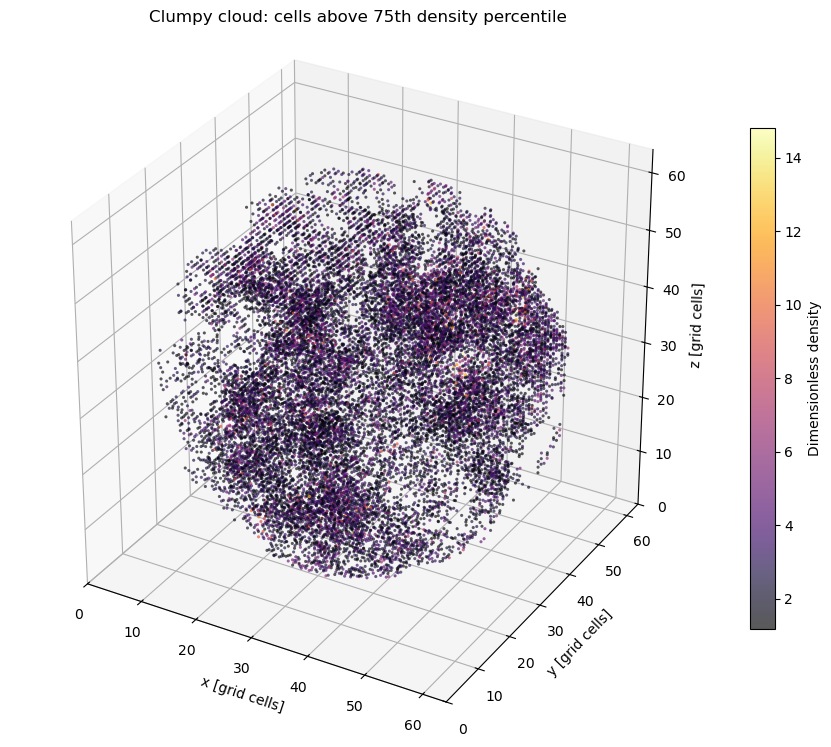

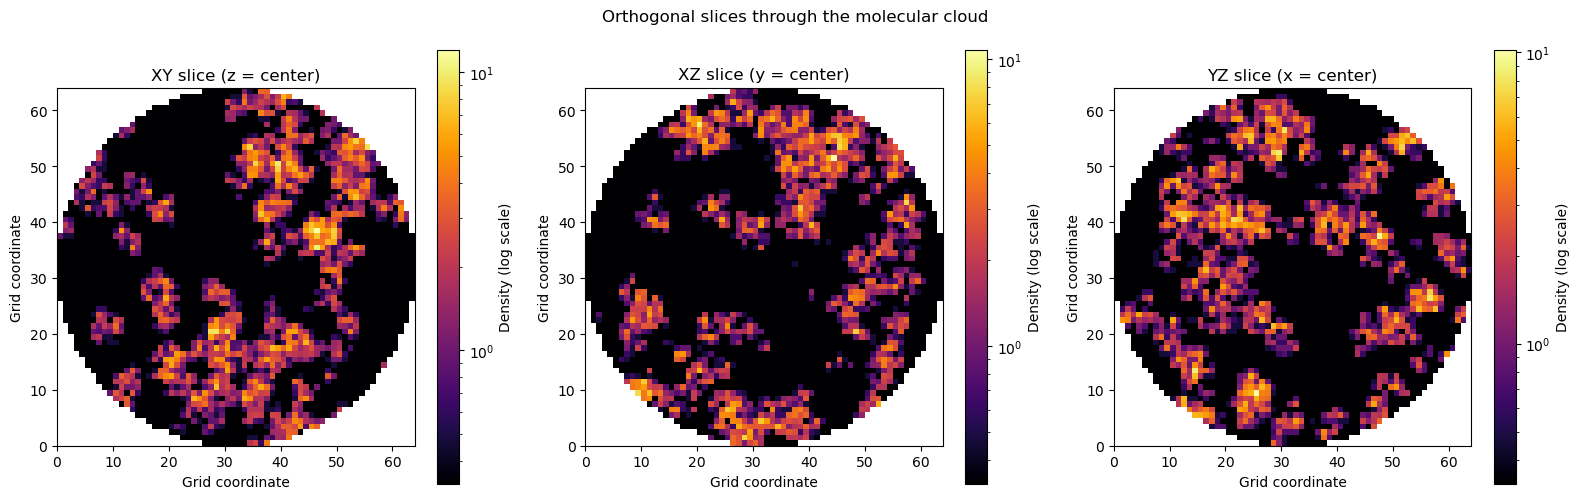

In [5]:
def plot_cloud_3d(density, mask, percentile=75, max_points=18000):
    """3-D scatter plot of high-density cells inside the spherical cloud."""
    values = density[mask]
    threshold = np.percentile(values, percentile)

    ix, iy, iz = np.where(mask & (density >= threshold))
    values_selected = density[ix, iy, iz]

    # Randomly thin the displayed cells if there are too many.
    if len(ix) > max_points:
        rng = np.random.default_rng(123)
        chosen = rng.choice(len(ix), size=max_points, replace=False)
        ix, iy, iz = ix[chosen], iy[chosen], iz[chosen]
        values_selected = values_selected[chosen]

    fig = plt.figure(figsize=(9, 8))
    ax = fig.add_subplot(111, projection="3d")
    scatter = ax.scatter(
        ix, iy, iz,
        c=values_selected,
        s=5,
        alpha=0.65,
        cmap="inferno",
        linewidths=0,
    )
    ax.set_xlim(0, density.shape[0])
    ax.set_ylim(0, density.shape[1])
    ax.set_zlim(0, density.shape[2])
    ax.set_box_aspect((1, 1, 1))
    ax.set_xlabel("x [grid cells]")
    ax.set_ylabel("y [grid cells]")
    ax.set_zlabel("z [grid cells]")
    ax.set_title(f"Clumpy cloud: cells above {percentile}th density percentile")
    fig.colorbar(scatter, ax=ax, shrink=0.65, label="Dimensionless density")
    plt.tight_layout()
    plt.show()


def plot_density_slices(density):
    """Plot XY, XZ, and YZ slices through the center of the cloud."""
    n = density.shape[0]
    c = n // 2

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    slices = [
        (density[:, :, c], "XY slice (z = center)"),
        (density[:, c, :], "XZ slice (y = center)"),
        (density[c, :, :], "YZ slice (x = center)"),
    ]

    for ax, (image, title) in zip(axes, slices):
        positive = image[image > 0]
        vmin = max(positive.min(), 1e-6)
        vmax = max(positive.max(), vmin * 1.01)
        im = ax.imshow(
            image.T,
            origin="lower",
            cmap="inferno",
            norm=LogNorm(vmin=vmin, vmax=vmax),
            extent=(0, n, 0, n),
        )
        ax.set_title(title)
        ax.set_xlabel("Grid coordinate")
        ax.set_ylabel("Grid coordinate")
        fig.colorbar(im, ax=ax, label="Density (log scale)")

    fig.suptitle("Orthogonal slices through the molecular cloud")
    plt.tight_layout()
    plt.show()


PLOT_PERCENTILE = 75
plot_cloud_3d(density, cloud_mask, percentile=PLOT_PERCENTILE)
plot_density_slices(density)

## 6. Inspect a selected clump

This cell identifies the highest-density cell and plots a zoomed region around it. Change `CLUMP_HALF_WIDTH` to control the displayed region. This is useful for checking the hierarchical substructure at a local scale.

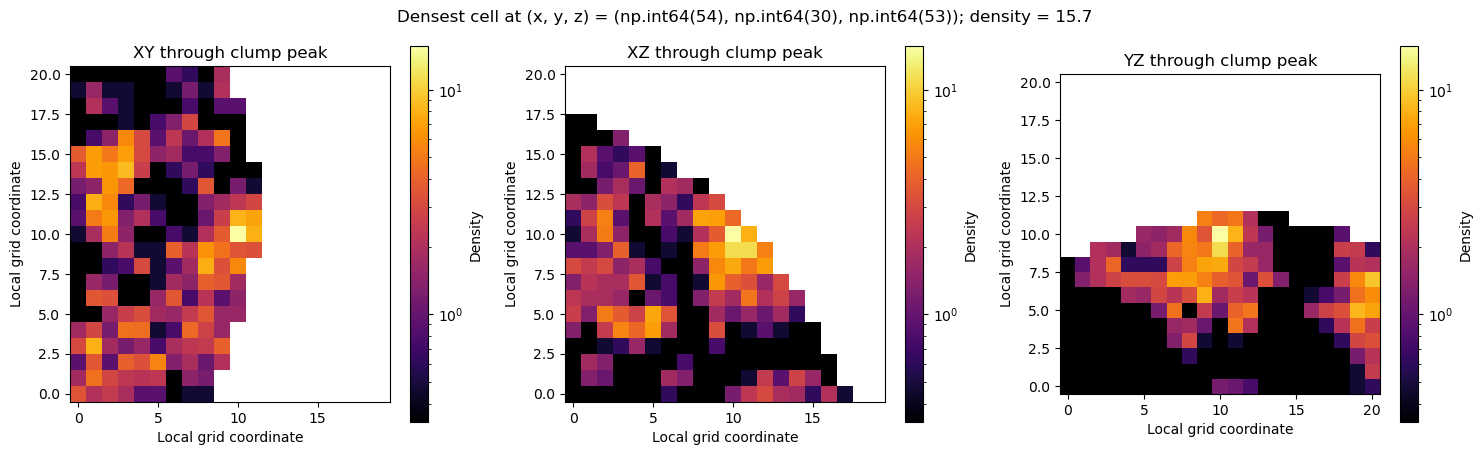

In [6]:
def plot_densest_clump(density, half_width=10):
    """Plot three slices through the maximum-density cell."""
    center = np.unravel_index(np.argmax(density), density.shape)
    n = density.shape[0]
    h = half_width

    bounds = [
        (max(0, center[0]-h), min(n, center[0]+h+1)),
        (max(0, center[1]-h), min(n, center[1]+h+1)),
        (max(0, center[2]-h), min(n, center[2]+h+1)),
    ]

    x0, x1 = bounds[0]
    y0, y1 = bounds[1]
    z0, z1 = bounds[2]

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    local_slices = [
        (density[x0:x1, y0:y1, center[2]], "XY through clump peak"),
        (density[x0:x1, center[1], z0:z1], "XZ through clump peak"),
        (density[center[0], y0:y1, z0:z1], "YZ through clump peak"),
    ]

    for ax, (arr, title) in zip(axes, local_slices):
        positive = arr[arr > 0]
        if positive.size:
            im = ax.imshow(
                arr.T,
                origin="lower",
                cmap="inferno",
                norm=LogNorm(vmin=max(positive.min(), 1e-6),
                             vmax=max(positive.max(), positive.min() * 1.01)),
            )
            fig.colorbar(im, ax=ax, label="Density")
        else:
            ax.imshow(arr.T, origin="lower", cmap="inferno")
        ax.set_title(title)
        ax.set_xlabel("Local grid coordinate")
        ax.set_ylabel("Local grid coordinate")

    fig.suptitle(f"Densest cell at (x, y, z) = {center}; density = {density[center]:.3g}")
    plt.tight_layout()
    plt.show()
    return center


densest_cell = plot_densest_clump(density, half_width=10)

## 7. Compare different fractal dimensions or random seeds

Run this cell to compare \(D=2.3\) and \(D=2.6\) while keeping the other parameters fixed. Different seeds generate different realizations of the same statistical prescription.

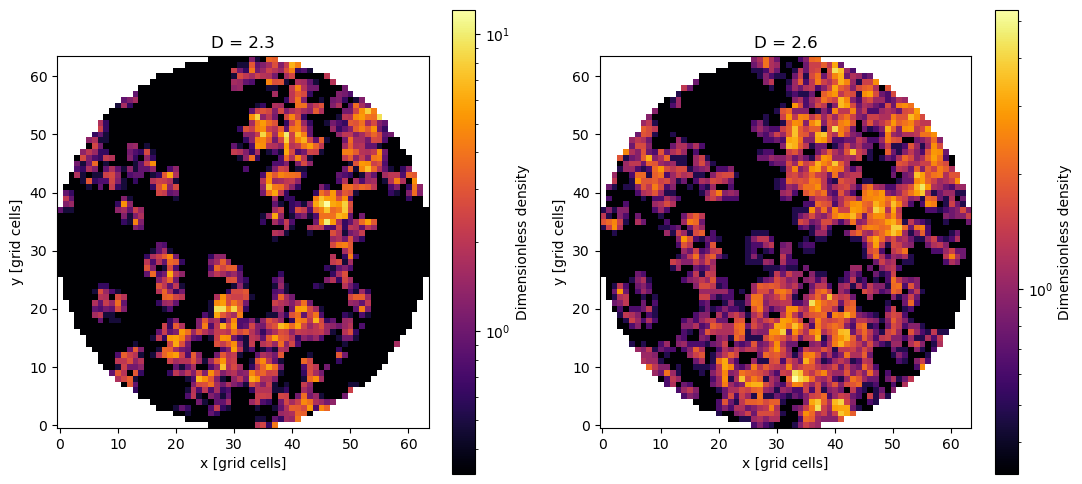

In [7]:
def generate_density_for_parameters(D, seed):
    pts = generate_fractal_points(
        grid_size=GRID_SIZE,
        n_branch=N_BRANCH,
        n_levels=N_LEVELS,
        fractal_dimension=D,
        seed=seed,
    )
    rho, _, mask = construct_cloud_density(
        pts,
        grid_size=GRID_SIZE,
        add_uniform_background=ADD_UNIFORM_BACKGROUND,
        uniform_mass_fraction=UNIFORM_MASS_FRACTION,
    )
    return rho, mask


comparison = {}
for D in (2.3, 2.6):
    comparison[D], _ = generate_density_for_parameters(D, RANDOM_SEED)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
center = GRID_SIZE // 2
for ax, D in zip(axes, (2.3, 2.6)):
    image = comparison[D][:, :, center]
    positive = image[image > 0]
    im = ax.imshow(
        image.T,
        origin="lower",
        cmap="inferno",
        norm=LogNorm(vmin=max(positive.min(), 1e-6), vmax=positive.max()),
    )
    ax.set_title(f"D = {D}")
    ax.set_xlabel("x [grid cells]")
    ax.set_ylabel("y [grid cells]")
    fig.colorbar(im, ax=ax, label="Dimensionless density")
plt.tight_layout()
plt.show()

## Notes for the radiative-transfer stage

1. Use `density` as the dimensionless spatial density field. It is zero outside the spherical cloud.
2. Use `mass_density` only after choosing a physical cloud radius and reference opacity. The optical-depth normalization in this notebook makes the **positive-x center-to-edge grid ray** equal to the requested `TAU0`; it is a discrete-grid convention and should be checked against your eventual ray marcher.
3. Use `number_density["H-1"]` (or another isotope key) if a later interaction model needs isotope number density.
4. Dust opacity is not generally determined by gas elemental \(Z,A\) alone. For the dust radiative-transfer model in Section 2.2, `KAPPA_REF_CM2_G` should represent the adopted dust-plus-gas mass extinction coefficient at the reference wavelength.
5. For reproducibility, keep `RANDOM_SEED` fixed. Change it to generate another cloud realization.

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# Use the grid resolution from your original notebook
GRID_SIZE = 64
N = GRID_SIZE

def spherical_mask(n=N):
    """Create a spherical cloud inscribed in a cubic grid."""
    q = np.arange(n) + 0.5
    x, y, z = np.meshgrid(q, q, q, indexing="ij")

    center = n / 2
    radius = n / 2

    return (
        (x-center)**2 +
        (y-center)**2 +
        (z-center)**2
    ) <= radius**2


def coordinate_grid(n=N):
    """Coordinates centered at the center of the cloud."""
    q = np.arange(n) + 0.5 - n/2
    return np.meshgrid(q, q, q, indexing="ij")


MASK = spherical_mask()


def normalize_density(raw_density, mask=MASK):
    """
    Normalize density to mean 1 inside the spherical cloud.
    Density outside the sphere is zero.
    """
    density = np.asarray(raw_density, dtype=float).copy()

    density[~mask] = 0

    mean_density = density[mask].mean()

    if mean_density <= 0:
        raise ValueError("Invalid density distribution")

    density /= mean_density

    return density

In [9]:
def bonnor_ebert_like(
    n=N,
    core_radius=8.0,
    alpha=2.5
):
    """
    Generate a Plummer-like centrally concentrated sphere.

    Parameters
    ----------
    core_radius : float
        Characteristic core radius in grid cells.
    alpha : float
        Controls how rapidly density decreases outside the core.
    """

    x, y, z = coordinate_grid(n)

    r = np.sqrt(x**2 + y**2 + z**2)

    raw_density = 1.0 / (
        1.0 + (r/core_radius)**alpha
    )

    mask = spherical_mask(n)

    return normalize_density(raw_density, mask)


density_BE = bonnor_ebert_like(
    core_radius=8,
    alpha=2.5
)

In [10]:
def gaussian_clumps(
    n=N,
    clumps=None,
    background=0.02
):
    """
    Generate a cloud containing configurable Gaussian clumps.

    Each clump has:
        center: position relative to cloud center
        sigma: Gaussian width in grid cells
        amplitude: peak density contribution
    """

    if clumps is None:
        clumps = [
            {
                "center": (-12, 0, 0),
                "sigma": 5,
                "amplitude": 1.0
            },
            {
                "center": (12, 0, 0),
                "sigma": 5,
                "amplitude": 3.0
            },
            {
                "center": (0, 12, 5),
                "sigma": 4,
                "amplitude": 2.0
            }
        ]

    x, y, z = coordinate_grid(n)

    raw_density = np.full(
        (n, n, n),
        background,
        dtype=float
    )

    for clump in clumps:

        cx, cy, cz = clump["center"]
        sigma = clump["sigma"]
        amplitude = clump["amplitude"]

        if sigma <= 0:
            raise ValueError("sigma must be positive")

        r_squared = (
            (x-cx)**2 +
            (y-cy)**2 +
            (z-cz)**2
        )

        raw_density += amplitude * np.exp(
            -r_squared / (2*sigma**2)
        )

    mask = spherical_mask(n)

    return normalize_density(raw_density, mask)


# Customize your clumps here
MY_CLUMPS = [
    {"center": (-12, 0, 0), "sigma": 5, "amplitude": 1.0},
    {"center": (12, 0, 0), "sigma": 5, "amplitude": 3.0},
    {"center": (0, 12, 5), "sigma": 4, "amplitude": 2.0},
]

density_G = gaussian_clumps(
    clumps=MY_CLUMPS,
    background=0.02
)

In [11]:
def filamentary_cloud(
    n=N,
    filament_sigma=4.0,
    filament_amplitude=1.0,
    clump_sigma=4.0,
    clump_amplitude=2.0,
    clump_positions=None
):
    """
    Generate a filament along the z-axis with embedded dense clumps.
    """

    if clump_positions is None:
        clump_positions = [
            (-4, 0, -15),
            (3, 1, 0),
            (0, -3, 15)
        ]

    x, y, z = coordinate_grid(n)

    radial_squared = x**2 + y**2

    # Radial Gaussian profile
    radial_profile = np.exp(
        -radial_squared / (2*filament_sigma**2)
    )

    # Finite longitudinal extent
    axial_profile = np.exp(
        -0.5 * (z/(0.42*n))**8
    )

    raw_density = (
        filament_amplitude *
        radial_profile *
        axial_profile
    )

    # Add dense cores along the filament
    for cx, cy, cz in clump_positions:

        r_squared = (
            (x-cx)**2 +
            (y-cy)**2 +
            (z-cz)**2
        )

        raw_density += clump_amplitude * np.exp(
            -r_squared / (2*clump_sigma**2)
        )

    mask = spherical_mask(n)

    return normalize_density(raw_density, mask)


density_F = filamentary_cloud()

In [12]:
def lognormal_cloud(
    n=N,
    spectral_index=3.0,
    log_density_sigma=1.0,
    seed=42
):
    """
    Generate a correlated lognormal-like density field.

    spectral_index:
        Controls the spatial power spectrum.

    log_density_sigma:
        Controls density contrast.

    seed:
        Random realization.
    """

    rng = np.random.default_rng(seed)

    # White noise in real space
    white_noise = rng.normal(
        size=(n, n, n)
    )

    # Fourier transform
    fourier_field = np.fft.fftn(white_noise)

    # Wavenumber coordinates
    kx = np.fft.fftfreq(n) * n
    ky = np.fft.fftfreq(n) * n
    kz = np.fft.fftfreq(n) * n

    KX, KY, KZ = np.meshgrid(
        kx, ky, kz,
        indexing="ij"
    )

    k = np.sqrt(
        KX**2 + KY**2 + KZ**2
    )

    k[0, 0, 0] = np.inf

    # Fourier-space power-law filter
    filter_k = k**(-spectral_index/2)

    filter_k[0, 0, 0] = 0

    # Correlated Gaussian field
    correlated = np.fft.ifftn(
        fourier_field * filter_k
    ).real

    correlated -= correlated.mean()
    correlated /= correlated.std() + 1e-12

    # Convert to positive lognormal-like density
    raw_density = np.exp(
        log_density_sigma * correlated
        - 0.5 * log_density_sigma**2
    )

    mask = spherical_mask(n)

    return normalize_density(raw_density, mask)


density_L = lognormal_cloud(
    spectral_index=3.0,
    log_density_sigma=1.0,
    seed=42
)

In [13]:
def plot_cloud_3d(
    density,
    title="Cloud",
    percentile=75,
    max_points=15000
):
    """
    Display cells above a density percentile in 3D.
    """

    mask = density > 0

    threshold = np.percentile(
        density[mask],
        percentile
    )

    ix, iy, iz = np.where(
        mask & (density >= threshold)
    )

    values = density[ix, iy, iz]

    # Limit points for faster rendering
    if len(ix) > max_points:

        rng = np.random.default_rng(123)

        indices = rng.choice(
            len(ix),
            max_points,
            replace=False
        )

        ix = ix[indices]
        iy = iy[indices]
        iz = iz[indices]
        values = values[indices]

    fig = plt.figure(figsize=(9, 8))

    ax = fig.add_subplot(
        111,
        projection="3d"
    )

    scatter = ax.scatter(
        ix, iy, iz,
        c=values,
        cmap="inferno",
        s=5,
        alpha=0.7
    )

    ax.set_xlim(0, GRID_SIZE)
    ax.set_ylim(0, GRID_SIZE)
    ax.set_zlim(0, GRID_SIZE)

    ax.set_box_aspect((1, 1, 1))

    ax.set_xlabel("X [cells]")
    ax.set_ylabel("Y [cells]")
    ax.set_zlabel("Z [cells]")

    ax.set_title(title)

    fig.colorbar(
        scatter,
        ax=ax,
        shrink=0.65,
        label="Relative density"
    )

    plt.tight_layout()
    plt.show()

In [14]:
def plot_cloud_slices(
    density,
    title="Cloud"
):
    """
    Plot XY, XZ, and YZ density slices through the cloud center.
    """

    c = density.shape[0] // 2

    slices = [
        (density[:, :, c], "XY plane"),
        (density[:, c, :], "XZ plane"),
        (density[c, :, :], "YZ plane")
    ]

    fig, axes = plt.subplots(
        1, 3,
        figsize=(16, 5)
    )

    for ax, (data, name) in zip(axes, slices):

        positive = data[data > 0]

        vmin = max(positive.min(), 1e-8)
        vmax = max(positive.max(), vmin*1.001)

        im = ax.imshow(
            data.T,
            origin="lower",
            cmap="inferno",
            norm=LogNorm(
                vmin=vmin,
                vmax=vmax
            )
        )

        ax.set_title(name)
        ax.set_xlabel("Grid coordinate")
        ax.set_ylabel("Grid coordinate")

        fig.colorbar(
            im,
            ax=ax,
            label="Relative density"
        )

    fig.suptitle(title, fontsize=15)

    plt.tight_layout()
    plt.show()

Visualizing: Bonnor-Ebert-like Sphere


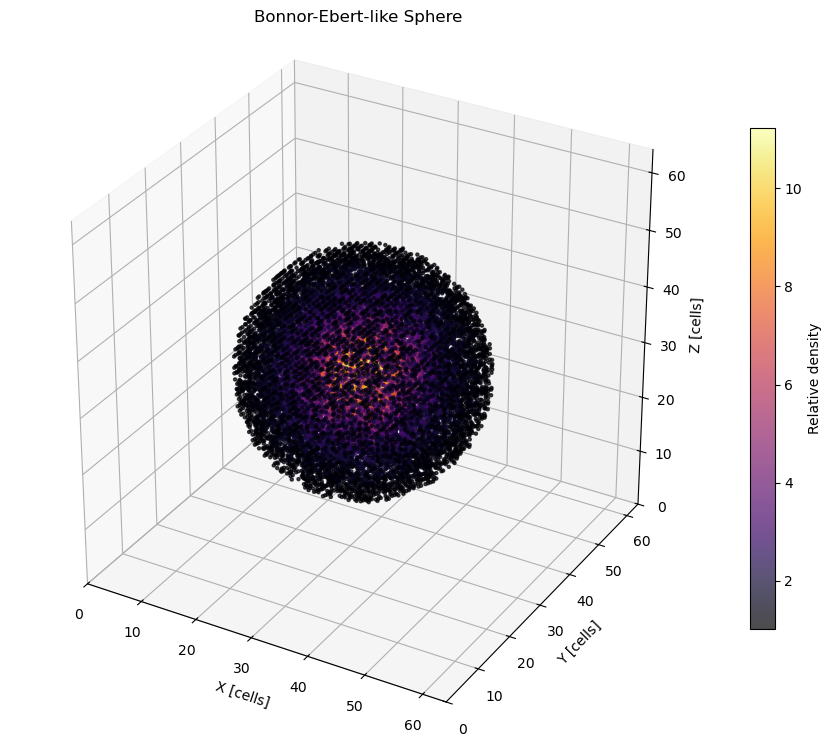

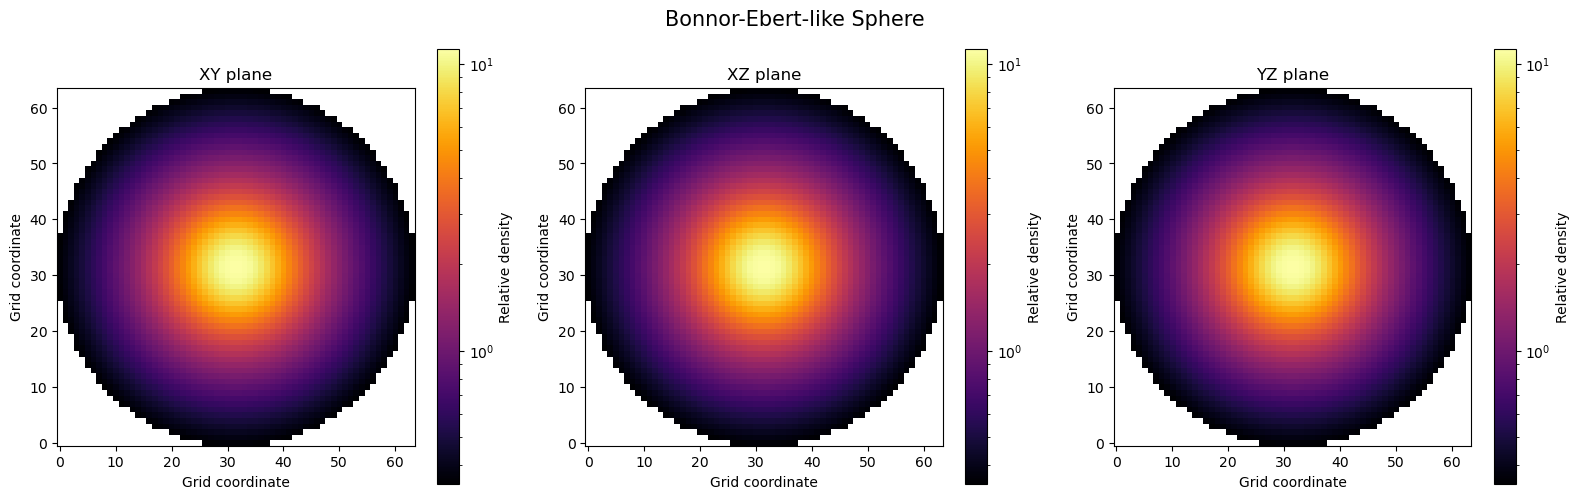

Visualizing: Gaussian Clumps


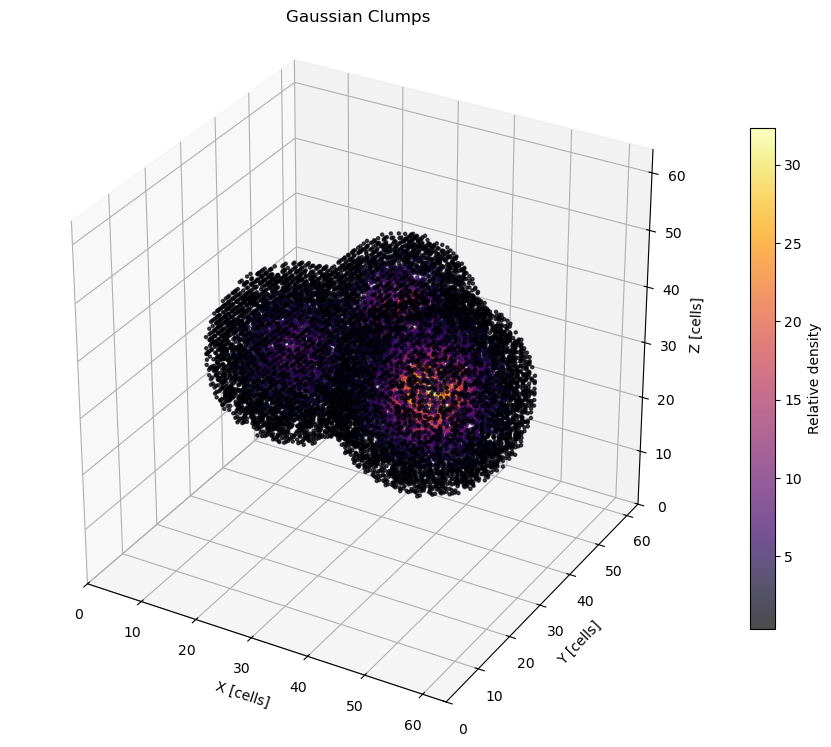

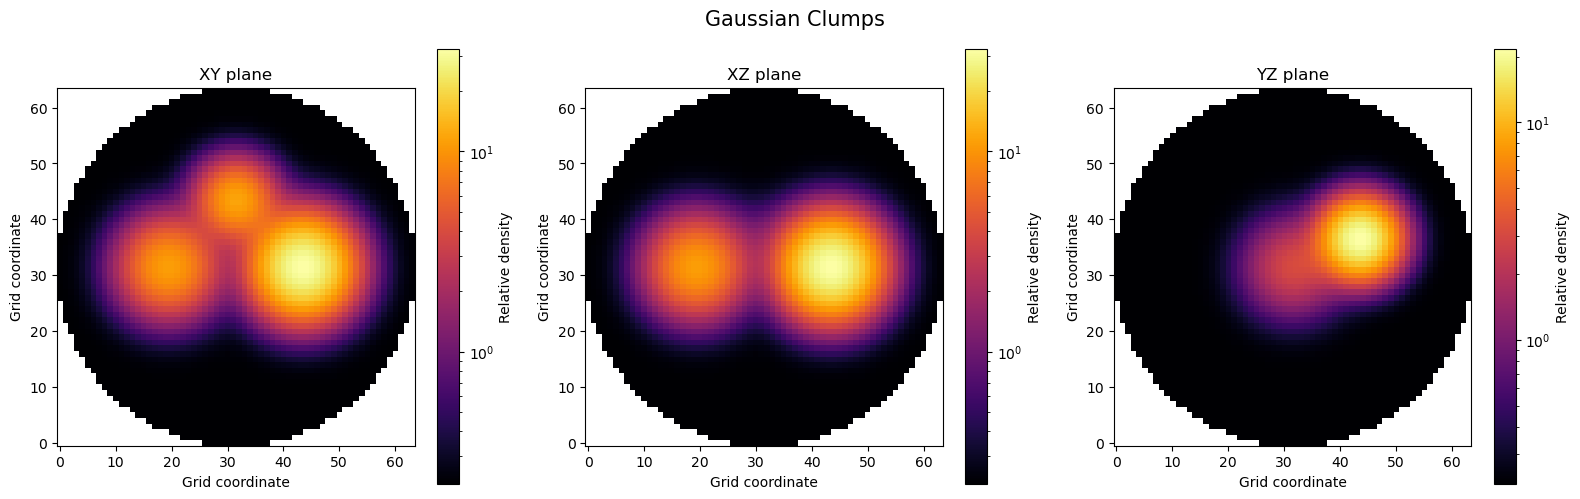

Visualizing: Filamentary Cloud


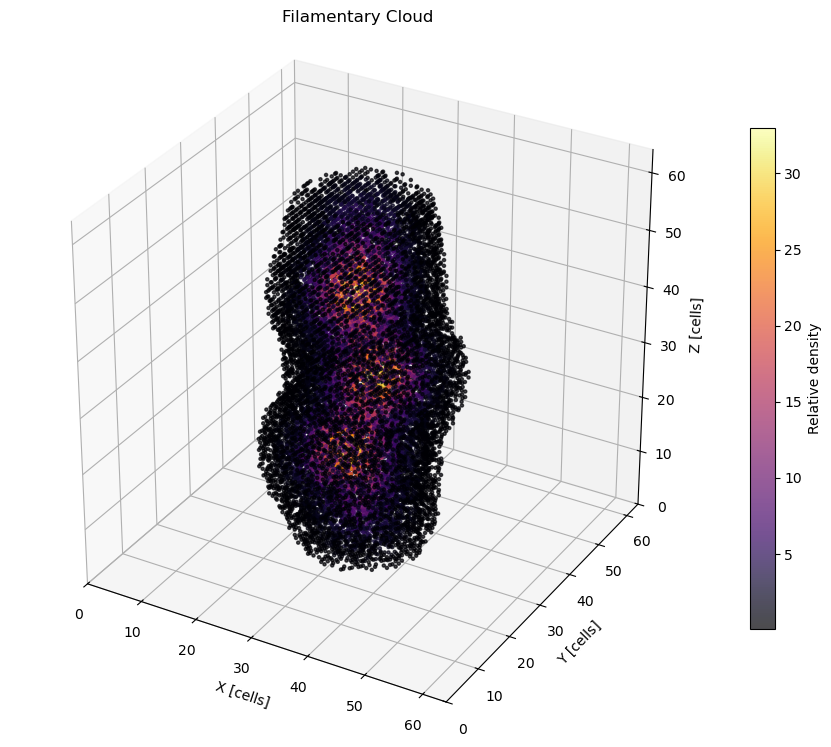

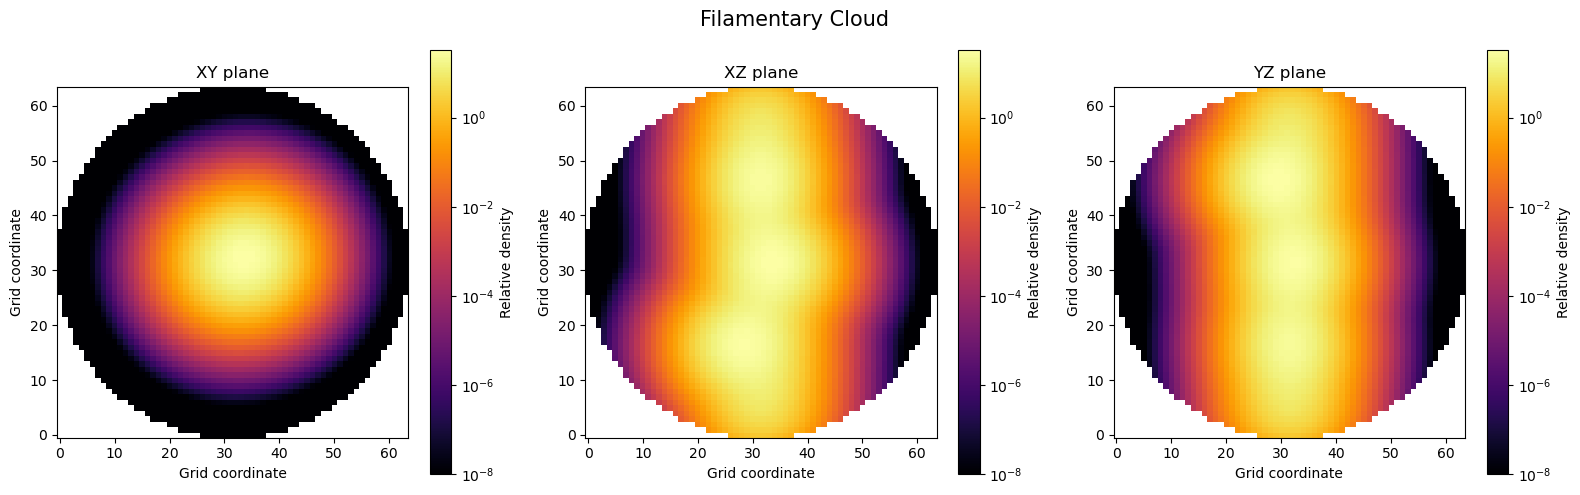

Visualizing: Lognormal Cloud


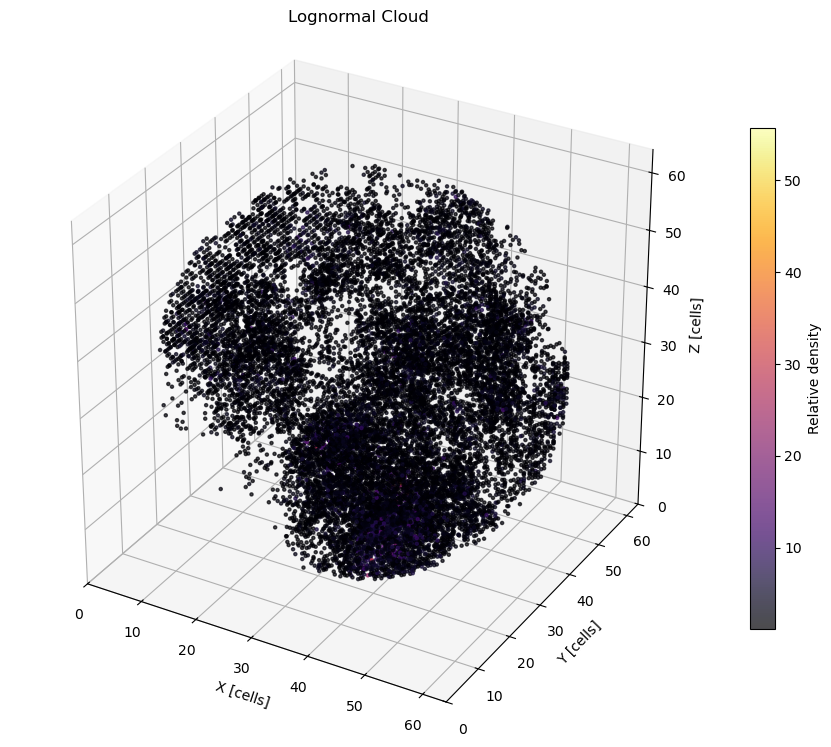

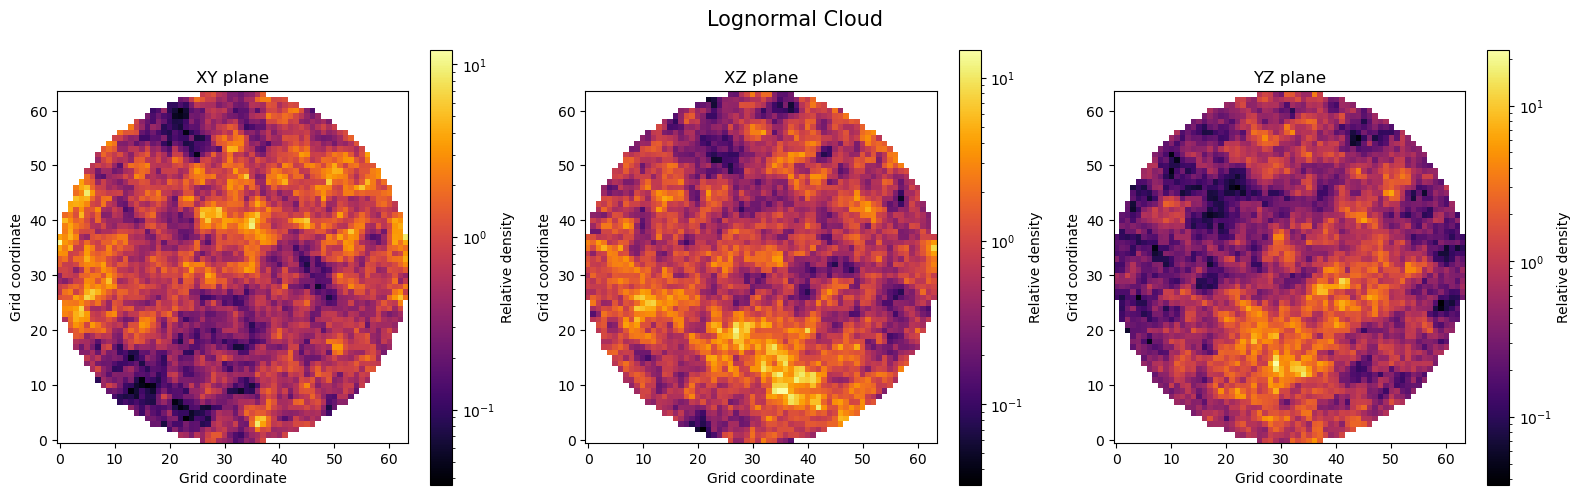

In [15]:
cloud_models = {
    "Bonnor-Ebert-like Sphere": density_BE,
    "Gaussian Clumps": density_G,
    "Filamentary Cloud": density_F,
    "Lognormal Cloud": density_L
}

for name, rho in cloud_models.items():

    print(f"Visualizing: {name}")

    plot_cloud_3d(
        rho,
        title=name,
        percentile=75
    )

    plot_cloud_slices(
        rho,
        title=name
    )

# Reverse Monte Carlo radiative transfer (Section 3 of the proposal)

Everything below uses the `density` / `cloud_mask` arrays built by the fractal generator above (the extra cloud models in the cells just before this section are left untouched and are not used here).

**Conventions**
- Lengths are in grid cells (cell size = 1, cloud radius $R$ = `GRID_SIZE/2`, centre at `GRID_SIZE/2`).
- The extinction optical depth per unit length is $\tau_{\rm cell}=\rho\,\tau_0/\Sigma_{\rm radial}$, where $\Sigma_{\rm radial}$ is the centre-to-edge column of the dimensionless density along $+x$ (same convention as `normalize_to_center_edge_tau`). So the central $+x$ ray has $\tau=\tau_0$ exactly.
- Scattering optical depth is $\omega\tau_{\rm ext}$ and absorption optical depth is $(1/\omega-1)$ times the scattering optical depth traversed, i.e. $(1-\omega)\tau_{\rm ext}$ (Eq. 3). A ray therefore never scatters when $\omega=0$ (straight line, $W=e^{-\tau}$) and never loses weight when $\omega=1$.
- On the final flight (the one that leaves the cloud) only the optical depth actually traversed is added to the absorption depth.
- Grid traversal is the Amanatides–Woo voxel walk; the exit test is $r>R$ (the sphere is convex, so a ray that leaves cannot return).


In [43]:

import subprocess, sys
try:
    import numba
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "numba"])
    import numba
from numba import njit, prange
import numpy as np, time
import matplotlib.pyplot as plt

# ---------------- RMC parameters ----------------
OMEGA = 0.5     # dust albedo
G_ASYM = 0.5    # Henyey-Greenstein asymmetry
M_RAYS = 1000     # reverse trajectories per sky direction
N_MU, N_PHI = 192, 384   # equal-area sky grid: Nd = N_MU*N_PHI directions
MAX_SCATTER = 100000

def tau_per_cell_from_density(rho, tau0):
    n = rho.shape[0]
    column = rho[n//2:, n//2, n//2].sum()       # centre -> +x edge, cells of unit length
    return rho * (tau0 / column)

tau_cell = tau_per_cell_from_density(density, TAU0)
R_CLOUD = GRID_SIZE / 2.0
print("centre->edge tau along +x:", tau_cell[GRID_SIZE//2:, GRID_SIZE//2, GRID_SIZE//2].sum())


centre->edge tau along +x: 10.000000000000002


In [44]:

@njit()
def _march(tc, sc, n, R, pos, d, tau_limit, tau_traveled_out):
    '''Walk from pos along d through the grid, accumulating tau (tc = tau per unit length per cell)
    until tau_limit is reached or the ray leaves the sphere.
    Returns (escaped, new_pos...) via arrays; tau actually traversed is written to tau_traveled_out[0].'''
    c = n / 2.0
    ix = int(np.floor(pos[0])); iy = int(np.floor(pos[1])); iz = int(np.floor(pos[2]))
    step = np.empty(3, np.int64); tmax = np.empty(3); tdelta = np.empty(3)
    for a in range(3):
        da = d[a]
        cell = (ix, iy, iz)[a]
        if da > 0:
            step[a] = 1; tdelta[a] = 1.0/da; tmax[a] = (cell + 1 - pos[a]) / da
        elif da < 0:
            step[a] = -1; tdelta[a] = -1.0/da; tmax[a] = (cell - pos[a]) / da
        else:
            step[a] = 0; tdelta[a] = 1e30; tmax[a] = 1e30
    t = 0.0; tau = 0.0
    while True:
        if ix < 0 or iy < 0 or iz < 0 or ix >= n or iy >= n or iz >= n:
            tau_traveled_out[0] = tau; return True, t
        a = 0
        if tmax[1] < tmax[a]: a = 1
        if tmax[2] < tmax[a]: a = 2
        seg = tmax[a] - t
        dtau = sc * tc[ix, iy, iz] * seg
        if tau + dtau >= tau_limit and dtau > 0:
            t += (tau_limit - tau) / (sc * tc[ix, iy, iz])
            tau_traveled_out[0] = tau_limit
            return False, t
        tau += dtau; t = tmax[a]
        if a == 0: ix += step[0]
        elif a == 1: iy += step[1]
        else: iz += step[2]
        tmax[a] += tdelta[a]
        # exit test at the new cell entry point
        px = pos[0] + d[0]*t - c; py = pos[1] + d[1]*t - c; pz = pos[2] + d[2]*t - c
        if px*px + py*py + pz*pz >= R*R:
            tau_traveled_out[0] = tau; return True, t


@njit()
def _hg_rotate(d, g, u1, u2):
    if abs(g) < 1e-6:
        cost = 1.0 - 2.0*u1
    else:
        cost = (1.0 + g*g - ((1.0 - g*g)/(1.0 - g + 2.0*g*u1))**2) / (2.0*g)   # Eq. (4)
    sint = np.sqrt(max(0.0, 1.0 - cost*cost)); phi = 2.0*np.pi*u2
    # orthonormal basis around d
    if abs(d[2]) < 0.999:
        ax, ay, az = -d[1], d[0], 0.0
    else:
        ax, ay, az = 0.0, -d[2], d[1]
    inv = 1.0/np.sqrt(ax*ax + ay*ay + az*az); ax*=inv; ay*=inv; az*=inv
    bx = d[1]*az - d[2]*ay; by = d[2]*ax - d[0]*az; bz = d[0]*ay - d[1]*ax
    out = np.empty(3)
    out[0] = cost*d[0] + sint*(np.cos(phi)*ax + np.sin(phi)*bx)
    out[1] = cost*d[1] + sint*(np.cos(phi)*ay + np.sin(phi)*by)
    out[2] = cost*d[2] + sint*(np.cos(phi)*az + np.sin(phi)*bz)
    nrm = np.sqrt(out[0]**2 + out[1]**2 + out[2]**2)
    return out/nrm


@njit()
def _one_trajectory(tc, n, R, pos0, d0, omega, g, maxscat):
    pos = pos0.copy(); d = d0.copy()
    tau_abs = 0.0; ttrav = np.empty(1)
    absfac = (1.0/omega - 1.0) if omega > 0 else 0.0
    for _ in range(maxscat):
        if omega > 0:
            tau_s = -np.log(1.0 - np.random.random())       # scattering optical depth to next event, Eq. (2)
            # tc is extinction; scattering depth = omega * extinction depth (passed as scale factor)
            escaped, t = _march(tc, omega, n, R, pos, d, tau_s, ttrav)
            tau_abs += absfac * ttrav[0]                     # Eq. (3), traversed part only
        else:
            escaped, t = _march(tc, 1.0, n, R, pos, d, 1e300, ttrav)
            return np.exp(-ttrav[0])                          # pure absorption: straight line
        if escaped:
            return np.exp(-tau_abs)                           # Eq. (5)
        pos = pos + d*t
        d = _hg_rotate(d, g, np.random.random(), np.random.random())
    return 0.0


@njit(parallel=True)
def _intensity_map(tc, n, R, pos0, dirs, M, omega, g, maxscat, seed):
    nd = dirs.shape[0]
    out = np.zeros(nd); err = np.zeros(nd)
    for i in prange(nd):
        np.random.seed(seed + i)
        s = 0.0; s2 = 0.0
        for m in range(M):
            w = _one_trajectory(tc, n, R, pos0, dirs[i], omega, g, maxscat)
            s += w; s2 += w*w
        mean = s/M
        out[i] = mean
        err[i] = np.sqrt(max(s2/M - mean*mean, 0.0)/max(M-1, 1))
    return out, err


@njit(parallel=True)
def _tau_map(tc, n, R, pos0, dirs):
    nd = dirs.shape[0]; out = np.zeros(nd); tt = np.empty(1)
    for i in prange(nd):
        tt = np.empty(1)
        _march(tc, 1.0, n, R, pos0, dirs[i], 1e300, tt)
        out[i] = tt[0]
    return out


In [45]:

def sky_directions(n_mu=N_MU, n_phi=N_PHI):
    '''Equal-area (uniform in cos(theta), phi) sky grid; returns dirs (Nd,3), lon, lat, shapes.'''
    mu = -1 + (np.arange(n_mu) + 0.5) * 2.0 / n_mu
    phi = (np.arange(n_phi) + 0.5) * 2*np.pi / n_phi
    MU, PH = np.meshgrid(mu, phi, indexing="ij")
    s = np.sqrt(1 - MU**2)
    dirs = np.stack([s*np.cos(PH), s*np.sin(PH), MU], -1).reshape(-1, 3)
    return dirs, PH, np.arcsin(MU)

def point_to_pos(p):
    '''p = offset from the cloud centre in grid cells -> absolute grid position.'''
    return np.asarray(p, float) + GRID_SIZE/2.0 + 1e-9

def sky_at(p, omega=OMEGA, g=G_ASYM, M=M_RAYS, tc=None, n_mu=N_MU, n_phi=N_PHI, seed=1):
    tc = tau_cell if tc is None else tc
    dirs, PH, LAT = sky_directions(n_mu, n_phi)
    pos = point_to_pos(p)
    I, err = _intensity_map(tc, tc.shape[0], R_CLOUD, pos, dirs, M, omega, g, MAX_SCATTER, seed)
    tau = _tau_map(tc, tc.shape[0], R_CLOUD, pos, dirs)
    shp = (n_mu, n_phi)
    return dict(I=I.reshape(shp), err=err.reshape(shp), tau=tau.reshape(shp),
                J=I.mean(), Jerr=np.sqrt((err**2).sum())/len(I), lon=PH, lat=LAT, pos=p)

t0 = time.time(); _ = sky_at((0, 0, 0), M=1, n_mu=8, n_phi=16); print("JIT warm-up: %.1f s" % (time.time()-t0))


JIT warm-up: 2.8 s


## Validation (Section 5 of the proposal)

Uniform sphere is built with the same $\tau_0$ for the comparison case. Checks: (1) $\omega=0$ against the deterministic ray-march $e^{-\tau}$; (2) $\omega=1$ gives $J/I_0=1$; (3) thin limit $\tau_0\to0$; (4) convergence in $M$ and $N_d$.

In [46]:

mask_f = cloud_mask.astype(float)
density_uniform = mask_f / mask_f[GRID_SIZE//2:, GRID_SIZE//2, GRID_SIZE//2].sum() * 0 + mask_f   # unit density in sphere
tau_uniform = tau_per_cell_from_density(density_uniform, TAU0)

test_pts = [(0,0,0), (10,5,-8), (20,0,0), (0,-24,6)]
print(f"{'point':>14s} | {'case':<34s} | result")
rows = []
for p in test_pts:
    # 1. pure absorption vs deterministic ray marching
    s = sky_at(p, omega=0.0, M=1)
    det = np.exp(-s['tau']).mean()
    print(f"{str(p):>14s} | omega=0  RMC  vs  <exp(-tau)>      | {s['J']:.6f} vs {det:.6f}   (max |dI| = {np.abs(s['I']-np.exp(-s['tau'])).max():.1e})")
    # 2. pure scattering
    s = sky_at(p, omega=1.0, g=G_ASYM, M=3)
    print(f"{str(p):>14s} | omega=1  J/I0 (should be 1)        | {s['J']:.6f}  (min/max over sky {s['I'].min():.3f}/{s['I'].max():.3f})")
# 3. optically thin limit
for t in (1e-3, 1e-2, 1e-1):
    tc_thin = tau_per_cell_from_density(density, t)
    s = sky_at((0,0,0), omega=OMEGA, M=5, tc=tc_thin)
    print(f"thin limit tau0={t:g}: J/I0 at centre = {s['J']:.5f}")


         point | case                               | result
     (0, 0, 0) | omega=0  RMC  vs  <exp(-tau)>      | 0.000287 vs 0.000287   (max |dI| = 0.0e+00)
     (0, 0, 0) | omega=1  J/I0 (should be 1)        | 1.000000  (min/max over sky 1.000/1.000)
   (10, 5, -8) | omega=0  RMC  vs  <exp(-tau)>      | 0.001068 vs 0.001068   (max |dI| = 0.0e+00)
   (10, 5, -8) | omega=1  J/I0 (should be 1)        | 1.000000  (min/max over sky 1.000/1.000)
    (20, 0, 0) | omega=0  RMC  vs  <exp(-tau)>      | 0.005873 vs 0.005873   (max |dI| = 0.0e+00)
    (20, 0, 0) | omega=1  J/I0 (should be 1)        | 1.000000  (min/max over sky 1.000/1.000)
   (0, -24, 6) | omega=0  RMC  vs  <exp(-tau)>      | 0.042268 vs 0.042268   (max |dI| = 0.0e+00)
   (0, -24, 6) | omega=1  J/I0 (should be 1)        | 1.000000  (min/max over sky 1.000/1.000)
thin limit tau0=0.001: J/I0 at centre = 0.99920
thin limit tau0=0.01: J/I0 at centre = 0.99205
thin limit tau0=0.1: J/I0 at centre = 0.92301


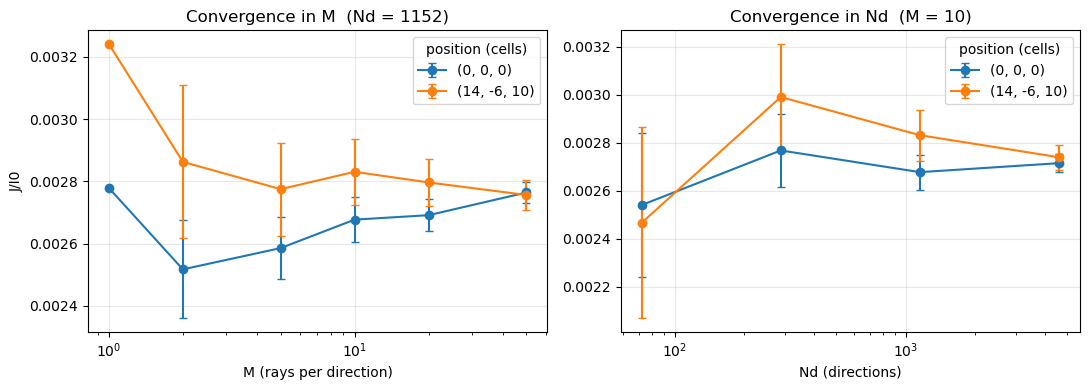

In [47]:

# 4. Convergence at the cloud centre and at an off-centre point in the clumpy cloud
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for p, col in (((0,0,0), "C0"), ((14,-6,10), "C1")):
    Ms = [1, 2, 5, 10, 20, 50]
    res = [sky_at(p, M=M, n_mu=24, n_phi=48, seed=7) for M in Ms]
    axes[0].errorbar(Ms, [r['J'] for r in res], [r['Jerr'] for r in res], fmt="o-", color=col, label=str(p), capsize=3)
    mus = [(6,12), (12,24), (24,48), (48,96)]
    res = [sky_at(p, M=10, n_mu=a, n_phi=b, seed=7) for a, b in mus]
    axes[1].errorbar([a*b for a, b in mus], [r['J'] for r in res], [r['Jerr'] for r in res], fmt="o-", color=col, label=str(p), capsize=3)
axes[0].set_xscale("log"); axes[0].set_xlabel("M (rays per direction)"); axes[0].set_ylabel("J/I0"); axes[0].set_title("Convergence in M  (Nd = 1152)")
axes[1].set_xscale("log"); axes[1].set_xlabel("Nd (directions)"); axes[1].set_title("Convergence in Nd  (M = 10)")
for a in axes: a.legend(title="position (cells)"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()


## Sky maps and optical-depth maps

For each chosen interior point we show three Mollweide panels (longitude $\phi$, latitude = $\arcsin\mu$): the **straight-line optical depth** $\tau(\hat k)$ from the point to the cloud surface, the **reverse-MC intensity** $I(\hat k)/I_0$, and the pure-absorption intensity $e^{-\tau}$ (what you would see with no scattering). The difference between the last two panels is the contribution of scattered light, which fills in the dark clumps.

In [ ]:

def moll(ax, lon, lat, Z, cmap, norm=None, label="", vmin=None, vmax=None):
    lon_c = lon - np.pi                      # centre the map on phi = pi
    # edges for pcolormesh
    nmu, nph = Z.shape
    mu_e = np.linspace(-1, 1, nmu+1); lat_e = np.arcsin(mu_e)
    lon_e = np.linspace(-np.pi, np.pi, nph+1)
    LON, LAT = np.meshgrid(lon_e, lat_e)
    m = ax.pcolormesh(LON, LAT, Z, cmap=cmap, norm=norm, vmin=None if norm else vmin, vmax=None if norm else vmax, shading="flat")
    ax.grid(alpha=.3); ax.set_xticklabels([]); 
    return m

def plot_sky(s, title=""):
    fig = plt.figure(figsize=(17, 4.6))
    ax1 = fig.add_subplot(131, projection="mollweide"); ax2 = fig.add_subplot(132, projection="mollweide"); ax3 = fig.add_subplot(133, projection="mollweide")
    m1 = moll(ax1, s['lon'], s['lat'], s['tau'], "magma_r", vmin=0, vmax=max(1e-3, s['tau'].max()))
    ax1.set_title("Optical depth to cloud surface, τ(k̂)")
    fig.colorbar(m1, ax=ax1, orientation="horizontal", pad=.08, shrink=.8, label="τ")
    Ipos = np.concatenate([s['I'][s['I']>0], np.exp(-s['tau']).ravel()])
    vmax = min(1.0, Ipos.max()*1.2); vmin = max(np.percentile(Ipos, 1), vmax*1e-8)
    nrm = LogNorm(vmin=vmin, vmax=vmax)
    m2 = moll(ax2, s['lon'], s['lat'], np.maximum(s['I'], vmin), "viridis", norm=nrm, vmin=vmin, vmax=vmax)
    ax2.set_title(f"RMC intensity I(k̂)/I0  (ω={OMEGA}, g={G_ASYM}, M={M_RAYS})")
    fig.colorbar(m2, ax=ax2, orientation="horizontal", pad=.08, shrink=.8, label="I/I0")
    m3 = moll(ax3, s['lon'], s['lat'], np.maximum(np.exp(-s['tau']), vmin), "viridis", norm=nrm, vmin=vmin, vmax=vmax)
    ax3.set_title("Direct light only, exp(-τ(k̂))")
    fig.colorbar(m3, ax=ax3, orientation="horizontal", pad=.08, shrink=.8, label="exp(-τ)")
    fig.suptitle(f"{title}   position (cells from centre) = {tuple(float(x) for x in s['pos'])},   <I>/I0 = J/I0 = {s['J']:.3g} ± {s['Jerr']:.2g}", y=1.02)
    plt.show()

# dark, self-shielded point: densest cell near the centre of the clumpy cloud; plus a few reference points
dens_c = np.where(cloud_mask, density, 0)
inner = (np.add.outer(np.add.outer((np.arange(GRID_SIZE)+.5-R_CLOUD)**2, (np.arange(GRID_SIZE)+.5-R_CLOUD)**2), (np.arange(GRID_SIZE)+.5-R_CLOUD)**2) < (0.6*R_CLOUD)**2)
densest = np.unravel_index(np.argmax(np.where(inner, density, 0)), density.shape)
p_dense = tuple(np.array(densest) + 0.5 - R_CLOUD)
print("densest cell within 0.6 R of the centre, offset:", p_dense, " density:", density[densest])

SKY_POINTS = {"Cloud centre": (0.0, 0.0, 0.0), "Densest clump (r<0.6R)": p_dense, "Near the edge (0.85 R)": (0.85*R_CLOUD, 0.0, 0.0)}
skies = {}
for name, p in SKY_POINTS.items():
    skies[name] = sky_at(p, M=M_RAYS, seed=11)
    plot_sky(skies[name], title=name)

uni = sky_at((0, 0, 0), M=M_RAYS, tc=tau_uniform, seed=11); plot_sky(uni, "Uniform sphere (same τ0), cloud centre")


densest cell within 0.6 R of the centre, offset: (np.float64(13.5), np.float64(7.5), np.float64(3.5))  density: 14.807318897907567


## Mean intensity $J/I_0$ vs radius, and the clumpy-vs-uniform comparison

Sample random interior points, estimate $J/I_0$ with RMC, and compare the distribution **by volume** and **by mass** with the uniform sphere (Section 4 of the proposal).

J-sampling took 10.2 s


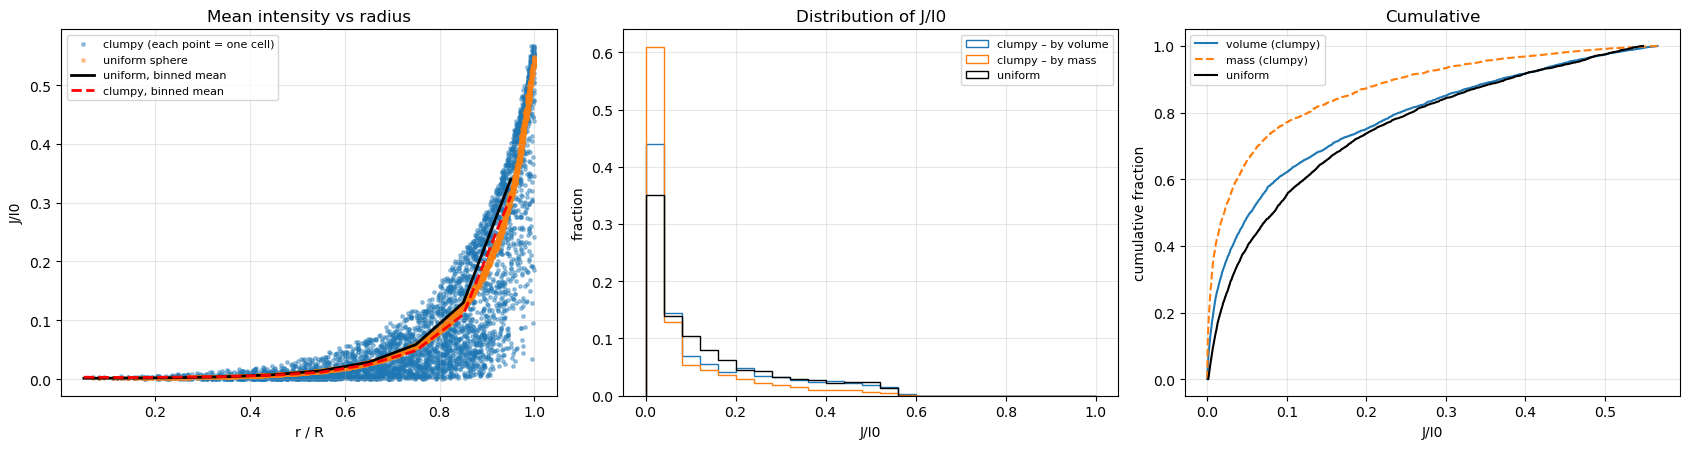

median J/I0 by volume (clumpy) = 0.054;  by mass = 0.021;  uniform median = 0.083


In [ ]:

@njit(parallel=True)
def _J_points(tc, n, R, pts, dirs, M, omega, g, maxscat, seed):
    out = np.zeros(pts.shape[0])
    for k in prange(pts.shape[0]):
        np.random.seed(seed + 7919*k)
        s = 0.0
        for i in range(dirs.shape[0]):
            for m in range(M):
                s += _one_trajectory(tc, n, R, pts[k], dirs[i], omega, g, maxscat)
        out[k] = s/(dirs.shape[0]*M)
    return out

def J_at_points(pts_cells, tc, omega=OMEGA, g=G_ASYM, M=5, n_mu=12, n_phi=24, seed=3):
    dirs, _, _ = sky_directions(n_mu, n_phi)
    return _J_points(tc, tc.shape[0], R_CLOUD, np.asarray(pts_cells, float), dirs, M, omega, g, MAX_SCATTER, seed)

# random cell-centre sample inside the cloud (cells are equal volume -> volume-weighted sample)
rng = np.random.default_rng(0)
idx = np.argwhere(cloud_mask)
sel = idx[rng.choice(len(idx), 4000, replace=False)]
pts = sel + 0.5
t0 = time.time()
J_clumpy = J_at_points(pts, tau_cell); J_unif = J_at_points(pts, tau_uniform)
print("J-sampling took %.1f s" % (time.time()-t0))
r = np.linalg.norm(pts - GRID_SIZE/2, axis=1) / R_CLOUD
w_mass = density[sel[:,0], sel[:,1], sel[:,2]]            # mass weight of the sampled cell

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].scatter(r, J_clumpy, s=6, alpha=.4, label="clumpy (each point = one cell)")
axes[0].scatter(r, J_unif, s=6, alpha=.4, label="uniform sphere")
rb = np.linspace(0, 1, 11); rc = .5*(rb[1:]+rb[:-1])
def _bm(J, a, b):
    m = (r>=a)&(r<b)
    return J[m].mean() if m.any() else np.nan
axes[0].plot(rc, [_bm(J_unif, a, b) for a, b in zip(rb[:-1], rb[1:])], "k-", lw=2, label="uniform, binned mean")
axes[0].plot(rc, [_bm(J_clumpy, a, b) for a, b in zip(rb[:-1], rb[1:])], "r--", lw=2, label="clumpy, binned mean")
axes[0].set_xlabel("r / R"); axes[0].set_ylabel("J/I0"); axes[0].legend(fontsize=8); axes[0].set_title("Mean intensity vs radius"); axes[0].grid(alpha=.3)

bins = np.linspace(0, 1.0, 26)
axes[1].hist(J_clumpy, bins, weights=np.ones_like(J_clumpy)/len(J_clumpy), histtype="step", lw=2, label="clumpy – by volume")
axes[1].hist(J_clumpy, bins, weights=w_mass/w_mass.sum(), histtype="step", lw=2, ls="--", label="clumpy – by mass")
axes[1].hist(J_unif, bins, weights=np.ones_like(J_unif)/len(J_unif), histtype="step", lw=2, color="k", label="uniform")
axes[1].set_xlabel("J/I0"); axes[1].set_ylabel("fraction"); axes[1].legend(fontsize=8); axes[1].set_title("Distribution of J/I0"); axes[1].grid(alpha=.3)

order = np.argsort(J_clumpy)
axes[2].plot(J_clumpy[order], np.cumsum(np.ones(len(order))/len(order)), label="volume (clumpy)")
axes[2].plot(J_clumpy[order], np.cumsum(w_mass[order])/w_mass.sum(), "--", label="mass (clumpy)")
o2 = np.argsort(J_unif); axes[2].plot(J_unif[o2], np.cumsum(np.ones(len(o2)))/len(o2), "k", label="uniform")
axes[2].set_xlabel("J/I0"); axes[2].set_ylabel("cumulative fraction"); axes[2].legend(fontsize=8); axes[2].set_title("Cumulative"); axes[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"median J/I0 by volume (clumpy) = {np.median(J_clumpy):.3f};  by mass = {J_clumpy[order][np.searchsorted(np.cumsum(w_mass[order])/w_mass.sum(), .5)]:.3f};  uniform median = {np.median(J_unif):.3f}")


## Fly-through

A sequence of sky maps along a straight path through the cloud (from the $-x$ edge to the $+x$ edge, offset in $y$ so that the path crosses clumps). Frames are written to `flythrough.gif`.

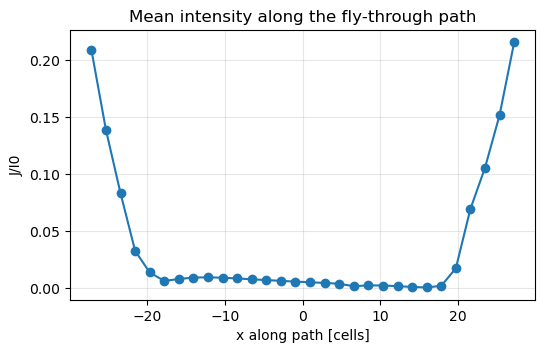

saved flythrough.gif with 30 frames


In [ ]:

import io
from matplotlib.backends.backend_agg import FigureCanvasAgg
try:
    import imageio.v2 as imageio
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imageio"]); import imageio.v2 as imageio

N_FRAMES = 30
path = [(x, 6.0, -4.0) for x in np.linspace(-0.85*R_CLOUD, 0.85*R_CLOUD, N_FRAMES)]
frames = []; Jpath = []
for k, p in enumerate(path):
    s = sky_at(p, M=M_RAYS, n_mu=36, n_phi=72, seed=100+k); Jpath.append(s['J'])
    fig = plt.figure(figsize=(11, 4.2))
    ax1 = fig.add_subplot(121, projection="mollweide"); ax2 = fig.add_subplot(122, projection="mollweide")
    m1 = moll(ax1, s['lon'], s['lat'], s['tau'], "magma_r", vmin=0, vmax=40); ax1.set_title("τ to surface")
    fig.colorbar(m1, ax=ax1, orientation="horizontal", pad=.08, shrink=.8)
    m2 = moll(ax2, s['lon'], s['lat'], np.maximum(s['I'], 1e-5), "viridis", norm=LogNorm(1e-5, 1)); ax2.set_title("I/I0 (RMC)")
    fig.colorbar(m2, ax=ax2, orientation="horizontal", pad=.08, shrink=.8)
    fig.suptitle(f"x = {p[0]:+.1f} cells   J/I0 = {s['J']:.3f}")
    canvas = FigureCanvasAgg(fig); canvas.draw()
    frames.append(np.asarray(canvas.buffer_rgba())[..., :3].copy()); plt.close(fig)
imageio.mimsave("flythrough.gif", frames, duration=0.25, loop=0)
plt.figure(figsize=(6, 3.5)); plt.plot([p[0] for p in path], Jpath, "o-"); plt.xlabel("x along path [cells]"); plt.ylabel("J/I0"); plt.grid(alpha=.3); plt.title("Mean intensity along the fly-through path"); plt.show()
print("saved flythrough.gif with", len(frames), "frames")


Gaussian clumps: +x centre->edge tau = 10.00


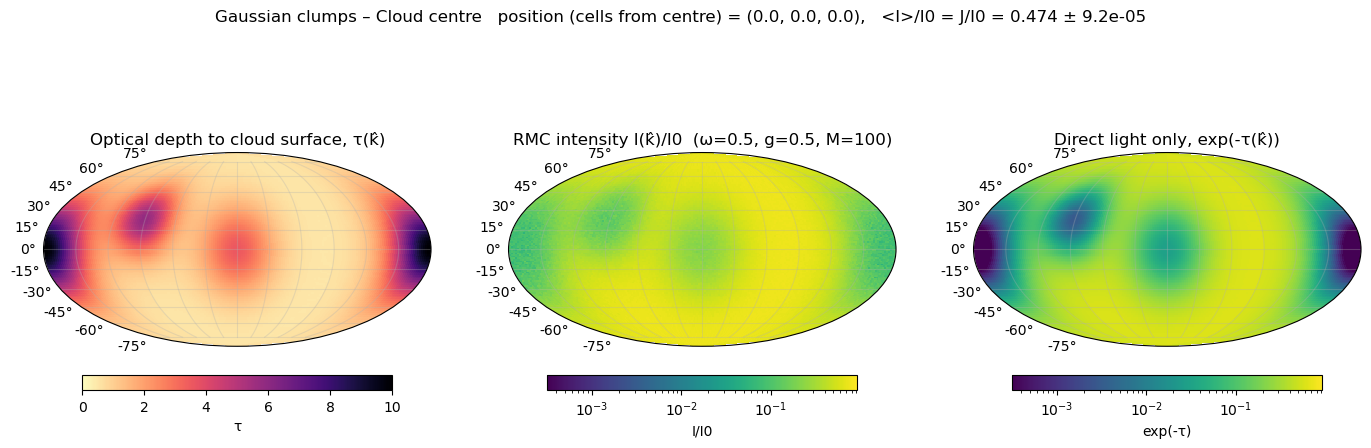

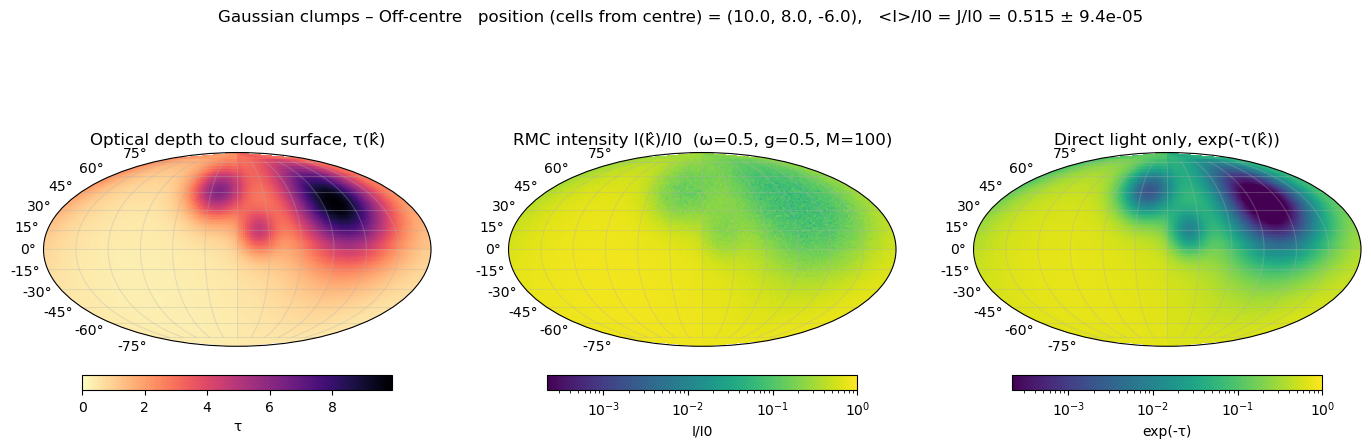

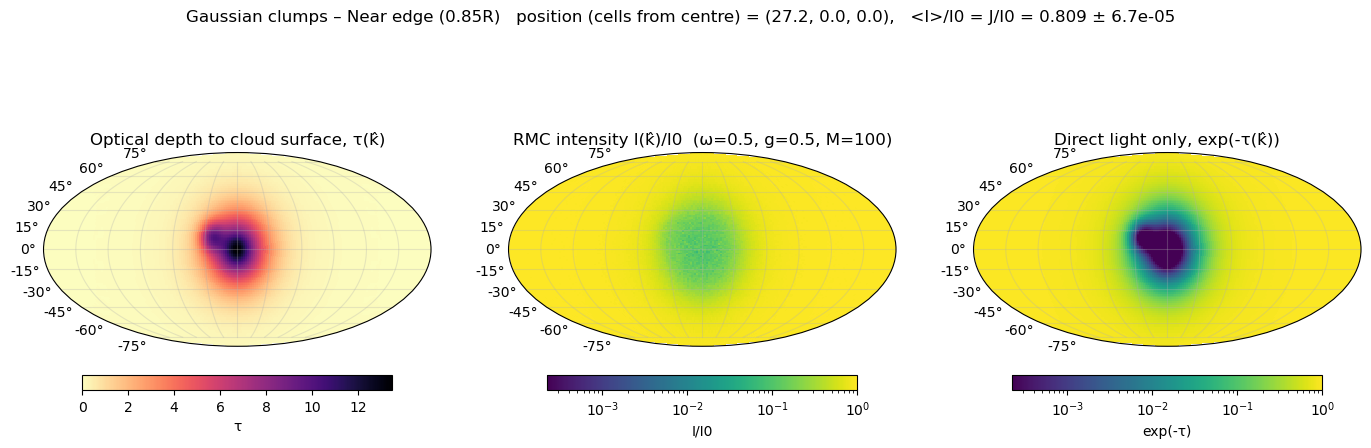

Lognormal: +x centre->edge tau = 10.00


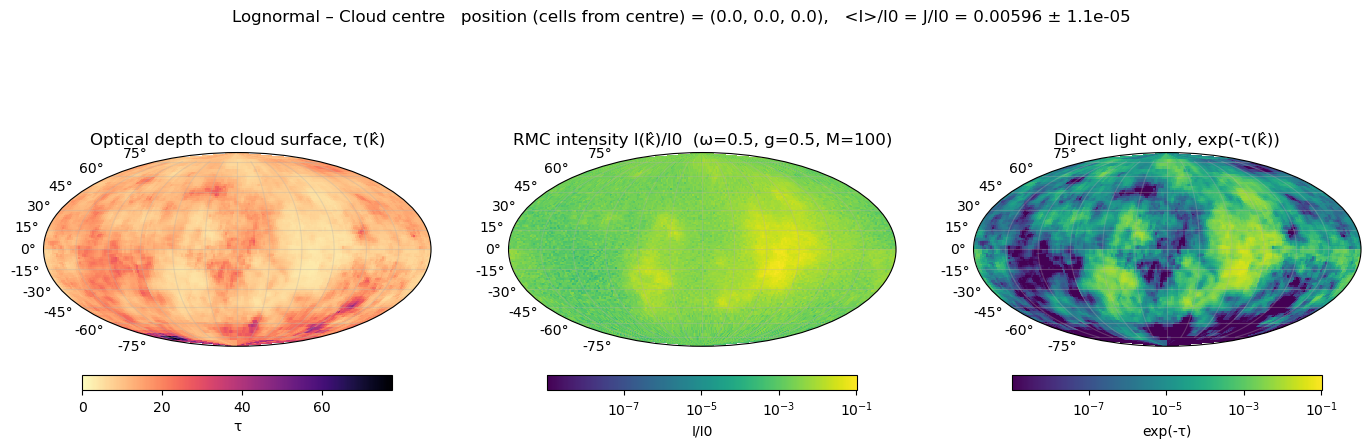

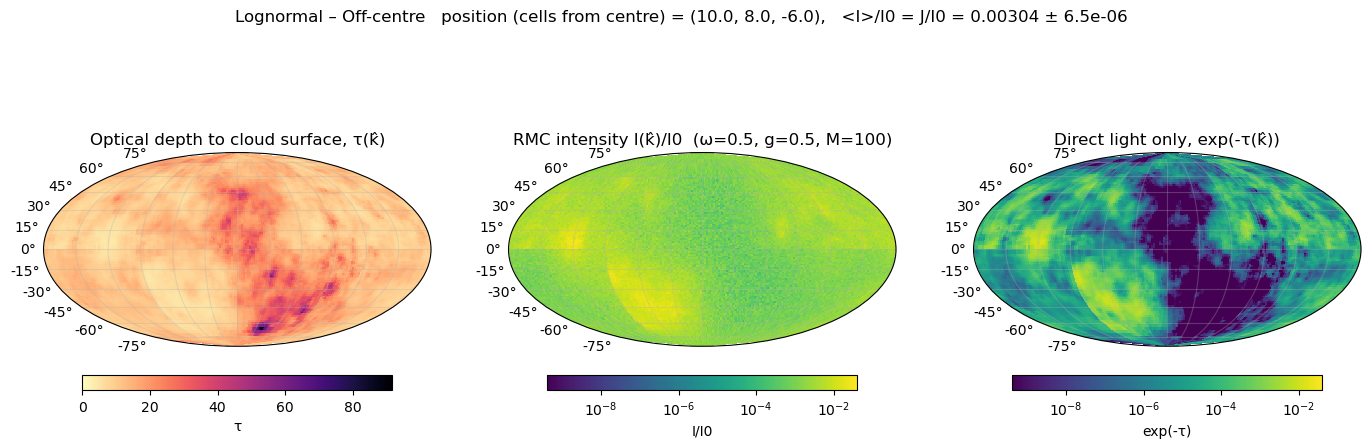

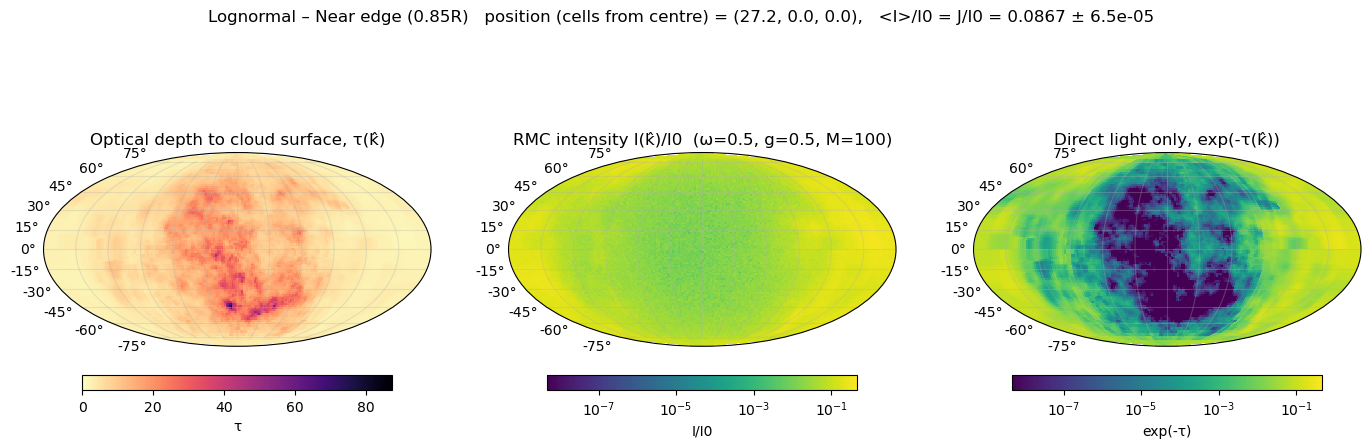

Filamentary: +x centre->edge tau = 10.00


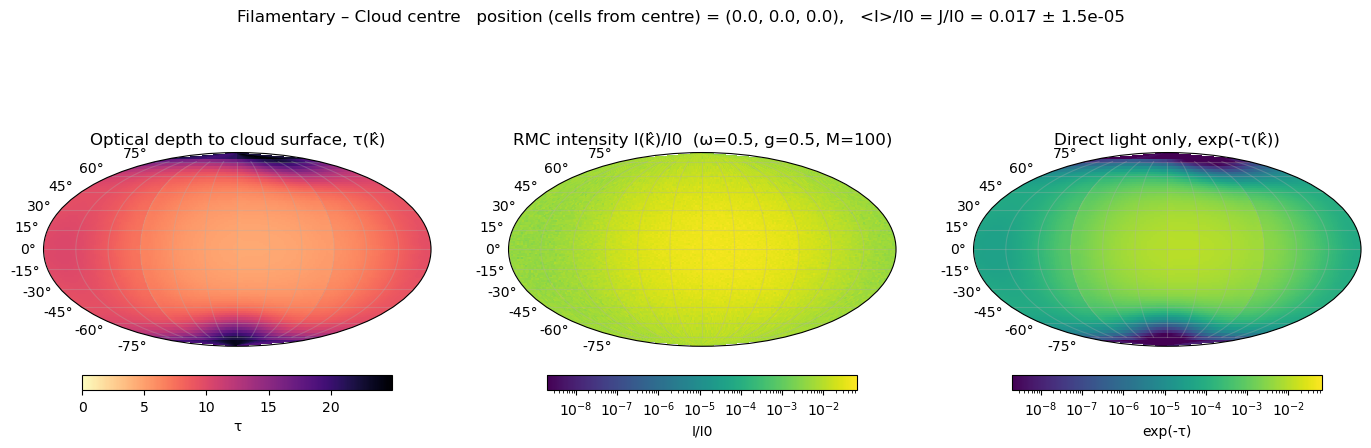

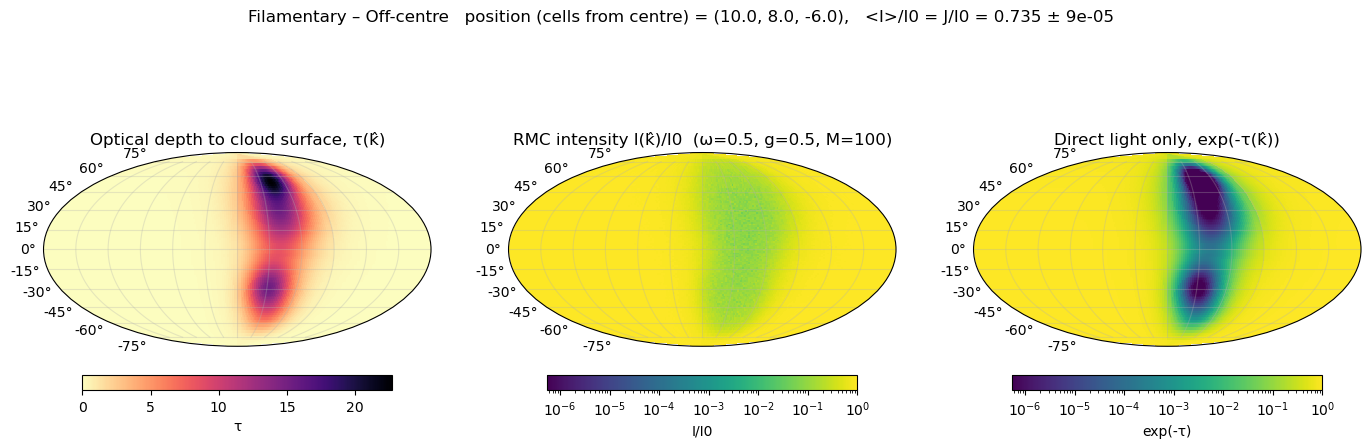

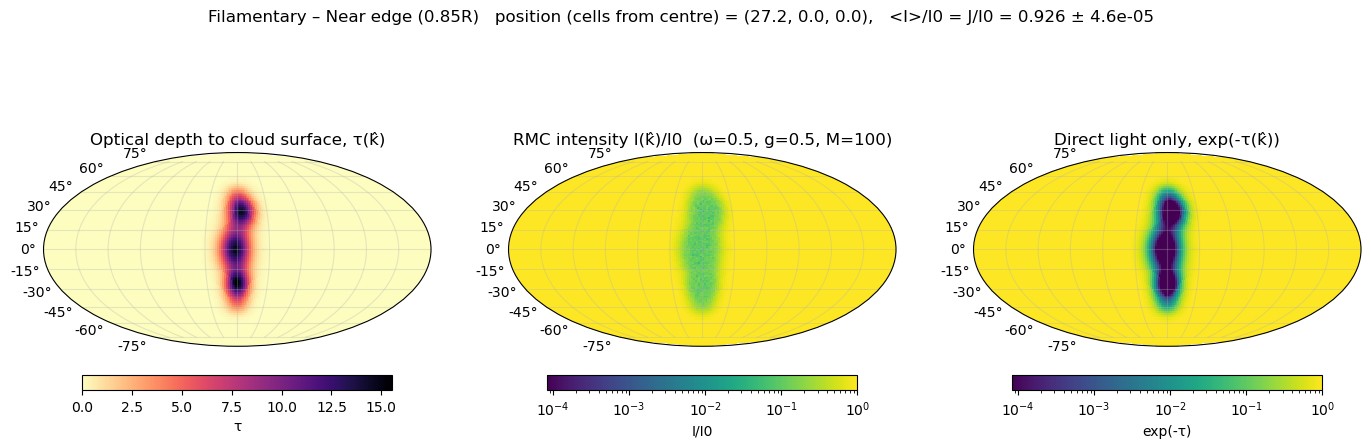


cloud                       Cloud centre            Off-centre     Near edge (0.85R)
Gaussian clumps                    0.474                 0.515                 0.809
Lognormal                        0.00596               0.00304                0.0867
Filamentary                        0.017                 0.735                 0.926


In [ ]:
# ---- RMC sky maps for the Gaussian-clump, lognormal and filamentary clouds ----
# Needs: the RMC cells above (sky_at, plot_sky, tau_per_cell_from_density, ...) and
#        density_G, density_L, density_F from the earlier cloud-model cells.

OTHER_CLOUDS = {
    "Gaussian clumps": density_G,
    "Lognormal":       density_L,
    "Filamentary":     density_F,
}
TAU0_OTHER = TAU0          # centre-to-edge optical depth; change here if you want a different value
OBSERVER_POINTS = {        # offsets from the cloud centre in grid cells
    "Cloud centre":   (0.0, 0.0, 0.0),
    "Off-centre":     (10.0, 8.0, -6.0),
    "Near edge (0.85R)": (0.85*R_CLOUD, 0.0, 0.0),
}

other_tc, other_skies = {}, {}
for cname, rho in OTHER_CLOUDS.items():
    rho = np.where(cloud_mask, rho, 0.0)               # keep only the inscribed sphere
    other_tc[cname] = tau_per_cell_from_density(rho, TAU0_OTHER)
    print(f"{cname}: +x centre->edge tau = {other_tc[cname][GRID_SIZE//2:, GRID_SIZE//2, GRID_SIZE//2].sum():.2f}")
    for pname, p in OBSERVER_POINTS.items():
        s = sky_at(p, M=M_RAYS, tc=other_tc[cname], seed=21)
        other_skies[(cname, pname)] = s
        plot_sky(s, title=f"{cname} – {pname}")

# one-row summary: <J/I0> at each observer point
print(f"\n{'cloud':<18s}" + "".join(f"{p:>22s}" for p in OBSERVER_POINTS))
for cname in OTHER_CLOUDS:
    print(f"{cname:<18s}" + "".join(f"{other_skies[(cname, p)]['J']:>22.3g}" for p in OBSERVER_POINTS))